# Phospho pathway coverage - August 3, 2015
Plot bar graphs showing the overlap between phosphorylation and pathway databases

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import seaborn as sns
import os

## Configure seaborn plotting defaults and set directories

In [2]:
sns.set() # Restore defaults
sns.set_palette('Set2', 8)
# Enlarge the text labels
sns.set_context('paper', font_scale=1.5)
sns.set_style('whitegrid')

inDir = os.path.join('..','..','evaluation','2015-02-16')
outDir = os.path.join('..','..','synthesis072614')

## Format the axis to show percentages
From http://matplotlib.org/examples/pylab_examples/histogram_percent_demo.html and modified to display integers

In [3]:
def to_percent(y, position):
    # Ignore the passed in position. This has the effect of scaling the default
    # tick locations.
    s = str(int(round(100 * y)))

    # The percent symbol needs escaping in latex
    if mpl.rcParams['text.usetex'] == True:
        return s + r'$\%$'
    else:
        return s + '%'

# Create the formatter using the function to_percent. This multiplies all the
# default labels by 100, making them all percentages
formatter = FuncFormatter(to_percent)

## Load the EGFR pathway overlaps
Only read 8 rows, the rest are all-pathway summaries, PPI network overlaps, etc.

In [4]:
egfrDf = pd.read_csv(os.path.join(inDir,'phospho-coverage-egfr.tsv'), sep='\t', nrows=8)

# Rename the columns
egfrDf.rename(columns={'phosphorylated resource nodes':'Pathway members that are phosphorylated',
                   'known phosphorylated nodes':'Phosphorylated proteins on pathway'}, inplace=True)

egfrDf = egfrDf.sort('Phosphorylated proteins on pathway')

# Map the pathway names to human-readable names
pathwayNames = {"kegg-4012":"KEGG ErbB", # http://www.genome.jp/kegg-bin/show_pathway?hsa04012
                    "kegg-4010":"KEGG MAPK", # http://www.genome.jp/kegg-bin/show_pathway?hsa04010
                    "layek":"Layek et al.", # http://bioinformatics.oxfordjournals.org/content/27/4/548/F4.large.jpg
                    "reactome-reactome-egfr":"Reactome EGFR",
                    "biocarta-egfr":"BioCarta EGF", # http://www.biocarta.com/pathfiles/h_egfpathway.asp
                    "science-signaling-egfr":"Science Signaling EGFR", # Not longer available online
                    "cellmap-commons-egfr":"Cancer Cell Map EGFR1", # http://www.pathwaycommons.org/pc/dbSnapshot.do?snapshot_id=8
                    "nci-nature-egfr":"PID ErbB1"} # http://pid.nci.nih.gov/search/pathway_landing.shtml?pathway_id=200101&source=NATURE&what=graphic&jpg=on
egfrDf['Pathway'] = egfrDf.apply(lambda row: pathwayNames[row['resource']], axis=1)
                    

## Plot the % of phosphorylated proteins that are on the EGFR pathways and the % of each pathway that is phosphorylated

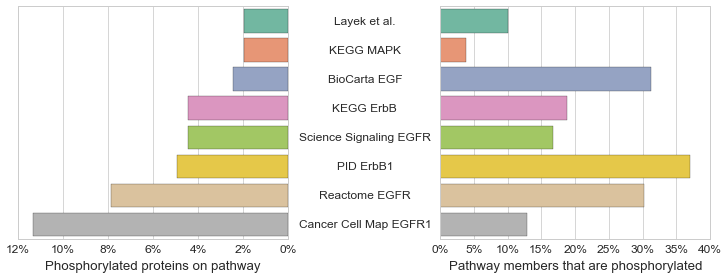

In [5]:
# Prepare the figure and subplots
fig, axes = plt.subplots(1, 2, figsize=(11,4)) 
plt.subplots_adjust(wspace=2)

# Plot the first subplot
xdata='Phosphorylated proteins on pathway'
ax1 = sns.barplot(x=xdata, y='Pathway', data=egfrDf, ax=axes[0])

# Flip the bar graph so that it can be stacked next to the second bar graph
ax1.invert_xaxis()
ax1.set_xlabel(xdata)
ax1.set_ylabel('')

# Hide the pathway names
ax1.get_yaxis().set_visible(False)

# Format the x-axis labels as percents
ax1.xaxis.set_major_formatter(formatter)

# Plot the second subplot
xdata = 'Pathway members that are phosphorylated'
ax2 = sns.barplot(x=xdata, y='Pathway', data=egfrDf, ax=axes[1])
ax2.set_xlabel(xdata)
ax2.set_ylabel('')

# Center the pathway names
ylabels = ax2.get_yticklabels()
for l in ylabels:
    l.set_horizontalalignment('center')
    l.set_x(-0.26)
    
# Format the x-axis labels as percents
ax2.xaxis.set_major_formatter(formatter)

# Save the figure as .png and .svg
plt.tight_layout()
plt.savefig(os.path.join(outDir, 'phospho-coverage-egfr-080315.png'), dpi=600)
plt.savefig(os.path.join(outDir, 'phospho-coverage-egfr-080315.svg'))

## Load the generic pathways
These are the union of all pathways from all databases when we could download full-database files.  Remove the EGFR-specific rows, the PPI row, and the Refiner row.

In [6]:
# First load the union of all EGFR resources
egfrDf = pd.read_csv(os.path.join(inDir,'phospho-coverage-egfr.tsv'), sep='\t')
egfrDf = egfrDf[egfrDf['resource'] == 'all-resources']

# Rename the resource to denote it is EGFR-specific
egfrDf.loc[:,'resource'] = 'all-resources-egfr'

allDf = pd.read_csv(os.path.join(inDir,'phospho-coverage-all-resources.tsv'), sep='\t')

# Select only the generic pathway resources
allDf = allDf.iloc[[4,9,10,12]]

# Add the EGFR pathway union
allDf = allDf.append(egfrDf)

# Rename the columns
allDf.rename(columns={'phosphorylated resource nodes':'Pathway members that are phosphorylated',
                   'known phosphorylated nodes':'Phosphorylated proteins on pathway'}, inplace=True)

allDf = allDf.sort('Phosphorylated proteins on pathway')

# Map the pathway names to human-readable names
pathwayNames = {'all-resources-egfr':'All EGFR',
                'biocarta':'All BioCarta',
                'reactome-reactome':'All Reactome',
                'nci-nature':'All PID',
                'all-resources':'All pathways'}                
allDf['Pathway'] = allDf.apply(lambda row: pathwayNames[row['resource']], axis=1)

## Plot the % of phosphorylated proteins that are on the union pathways and the % of the union that is phosphorylated

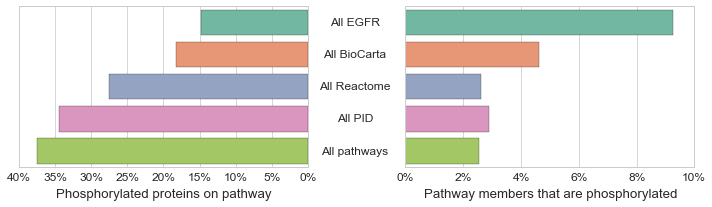

In [7]:
# Prepare the figure and subplots
fig, axes = plt.subplots(1, 2, figsize=(10,3)) 
plt.subplots_adjust(wspace=.35)

# Plot the first subplot
xdata='Phosphorylated proteins on pathway'
ax1 = sns.barplot(x=xdata, y='Pathway', data=allDf, ax=axes[0])

# Flip the bar graph so that it can be stacked next to the second bar graph
ax1.invert_xaxis()
ax1.set_xlabel(xdata)
ax1.set_ylabel('')

# Hide the pathway names
ax1.get_yaxis().set_visible(False)

# Format the x-axis labels as percents
ax1.xaxis.set_major_formatter(formatter)

# Plot the second subplot
xdata = 'Pathway members that are phosphorylated'
ax2 = sns.barplot(x=xdata, y='Pathway', data=allDf, ax=axes[1])
ax2.set_xlabel(xdata)
ax2.set_ylabel('')

# Center the pathway names
ylabels = ax2.get_yticklabels()
for l in ylabels:
    l.set_horizontalalignment('center')
    l.set_x(-0.155)
    
# Format the x-axis labels as percents
ax2.xaxis.set_major_formatter(formatter)

# Save the figure as .png and .svg
plt.tight_layout()
plt.savefig(os.path.join(outDir, 'phospho-coverage-all-resources-080315.png'), dpi=600)
plt.savefig(os.path.join(outDir, 'phospho-coverage-all-resources-080315.svg'))

## To visualize color palettes

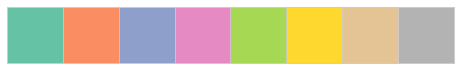

In [8]:
sns.palplot(sns.color_palette("Set2", 8))